In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

1. Loading and checking the dataset



In [4]:
df = pd.read_csv('/content/samplesuperstore.csv')

In [5]:
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [6]:

print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Duplicate rows:
0


2. Data transformation and exploratory analysis.

In [7]:
# Convert date columns
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y"
)

In [8]:
# Create time-based features
df["Order Year"] = df["Order Date"].dt.year
df["Order Month"] = df["Order Date"].dt.to_period("M")

In [9]:
# Calculate shipping duration
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

In [10]:
# Calculate row-level profit margin
df["Profit Margin %"] = np.where(
    df["Sales"] != 0,
    df["Profit"] / df["Sales"] * 100,
    np.nan
)

display(df.head())


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Shipping Days,Profit Margin %
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2023,2023-01,4,33.75
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2023,2023-01,4,-155.00
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Labels,Avery 508,11.784,3,0.2,4.2717,2023,2023-01,4,36.25
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2023,2023-01,4,-23.75
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,2023,2023-01,7,25.00


3. Calculating overall business KPIs

In [11]:

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else np.nan
)

print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Profit Margin: {profit_margin:.2f}%")


Total Sales: 2,326,534.35
Total Profit: 292,296.81
Total Orders: 5,111
Total Customers: 804
Profit Margin: 12.56%


4. Monthly sales and profit trends

,Order Month,Sales,Profit,Sales Growth %
0,2023-01-01,14518.055,2539.3907,NaN
1,2023-02-01,4519.892,862.3084,-68.867097
2,2023-03-01,56933.909,693.4499,1159.629854
3,2023-04-01,28295.345,3488.8352,-50.301419
4,2023-05-01,26319.767,3196.3918,-6.981989


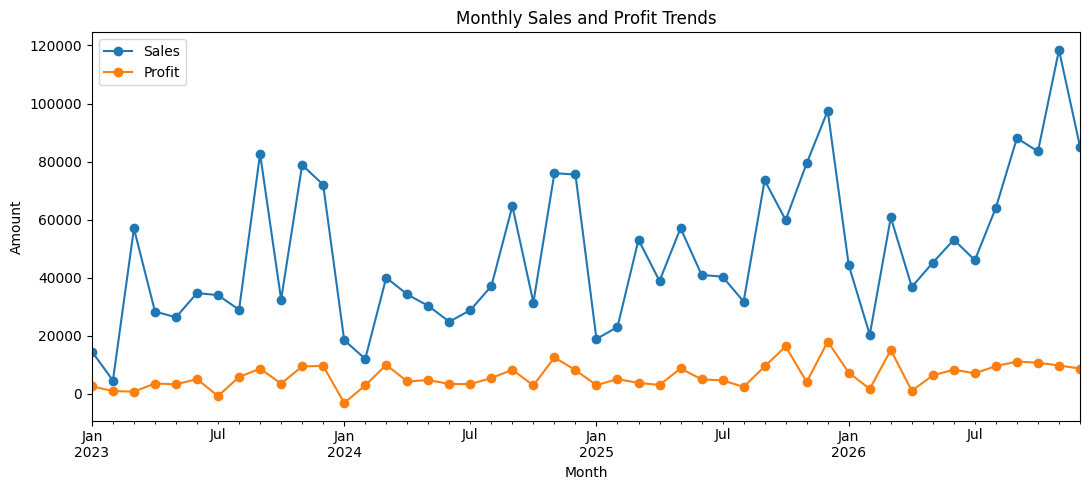

In [12]:

monthly = (
    df.groupby("Order Month")[["Sales", "Profit"]]
    .sum()
    .reset_index()
)

monthly["Order Month"] = (
    monthly["Order Month"].dt.to_timestamp()
)

monthly["Sales Growth %"] = (
    monthly["Sales"].pct_change() * 100
)

display(monthly.head())

ax = monthly.plot(
    x="Order Month",
    y=["Sales", "Profit"],
    figsize=(11, 5),
    marker="o"
)

ax.set_title("Monthly Sales and Profit Trends")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
plt.tight_layout()
plt.show()


In [ ]:
5. Category-level profitabilites

In [13]:

category = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order ID", "nunique")
    )
    .reset_index()
)

category["Profit Margin %"] = np.where(
    category["Sales"] != 0,
    category["Profit"] / category["Sales"] * 100,
    np.nan
)

display(
    category.sort_values("Profit", ascending=False)
)


,Category,Sales,Profit,Orders,Profit Margin %
2,Technology,839893.2790,146543.3756,1560,17.447857
1,Office Supplies,731893.3140,126023.4434,3812,17.218827
0,Furniture,754747.7613,19729.9956,1819,2.614118


6. Analysing the impact of discounts.

,Discount Band,Sales,Profit,Transactions,Profit Margin %
0,No Discount,1.105324e+06,326718.5872,4925,29.558632
1,0-20%,8.564504e+05,101598.9132,3854,11.862790
2,20-40%,2.354653e+05,-35990.9575,464,-15.285038
3,40-60%,7.150945e+04,-29163.8864,226,-40.783260
4,60-100%,5.778541e+04,-70865.8419,725,-122.636215


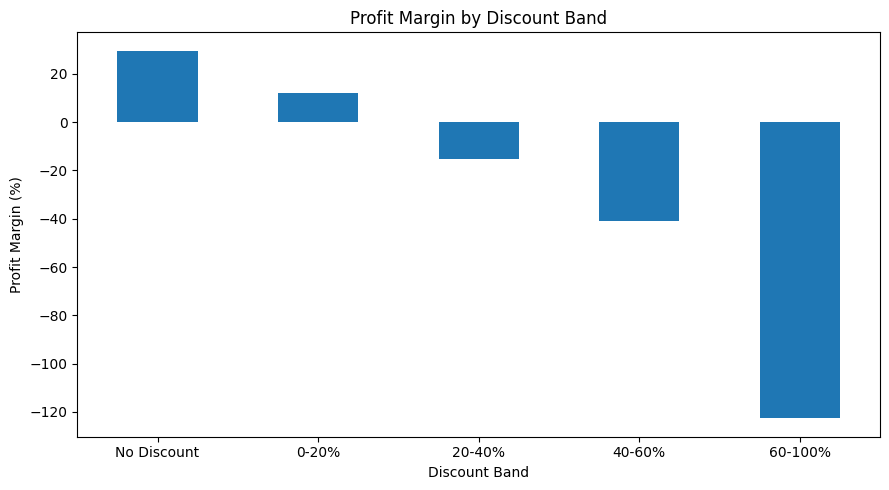

In [14]:

# Create discount ranges
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.2, 0.4, 0.6, 1.0],
    labels=[
        "No Discount",
        "0-20%",
        "20-40%",
        "40-60%",
        "60-100%"
    ]
)

discount_analysis = (
    df.groupby("Discount Band", observed=True)
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Transactions=("Order ID", "count")
    )
    .reset_index()
)

discount_analysis["Profit Margin %"] = np.where(
    discount_analysis["Sales"] != 0,
    discount_analysis["Profit"]
    / discount_analysis["Sales"] * 100,
    np.nan
)

display(discount_analysis)

ax = discount_analysis.plot(
    x="Discount Band",
    y="Profit Margin %",
    kind="bar",
    legend=False,
    figsize=(9, 5)
)

ax.set_title("Profit Margin by Discount Band")
ax.set_xlabel("Discount Band")
ax.set_ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


7. Customer value analysis



In [15]:

customers = (
    df.groupby(["Customer ID", "Customer Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

customers["Average_Order_Value"] = (
    customers["Total_Sales"]
    / customers["Total_Orders"]
)

top_customers = customers.nlargest(
    10, "Total_Sales"
)

display(top_customers)


,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Orders,Average_Order_Value
711,SM-20320,Sean Miller,25043.050,-1980.7393,5,5008.610000
752,TC-20980,Tamara Chand,19052.218,8981.3239,5,3810.443600
632,RB-19360,Raymond Buch,15117.339,6976.0959,6,2519.556500
741,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,3648.905000
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,1447.357100
443,KL-16645,Ken Lonsdale,14175.229,806.8550,12,1181.269083
680,SC-20095,Sanjit Chand,14142.334,5757.4119,9,1571.370444
328,HL-15040,Hunter Lopez,12873.298,5622.4292,6,2145.549667
694,SE-20110,Sanjit Engle,12209.438,2650.6769,11,1109.948909
132,CC-12370,Christopher Conant,12129.072,2177.0493,5,2425.814400


Saving the cleaned dataset

In [16]:

# Convert Period values to strings for CSV export
export_df = df.copy()

export_df["Order Month"] = (
    export_df["Order Month"].astype(str)
)

export_df.to_csv(
    "superstore_cleaned.csv",
    index=False
)

from google.colab import files
files.download("superstore_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>